Time Series 
---
1. Decomposition 
2. Resampling 
3. Centered Moving Average / Rolling Mean
4. Trailing Rolling Mean
5. Simple Exponential Method
6. Holt's Linear Trend
7. Holt's Exponential Trend
8. Additive Damp Trend
9. Holt Winters Additive Method
10. Holt Winters Multiplicative Method

base kernel

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [2]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv")
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


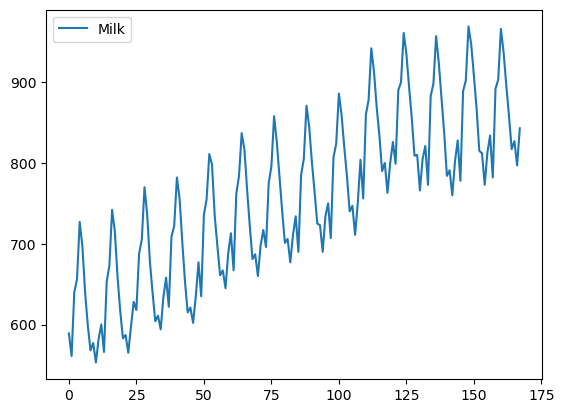

In [3]:
df.plot()
plt.show()

Decomposition
-

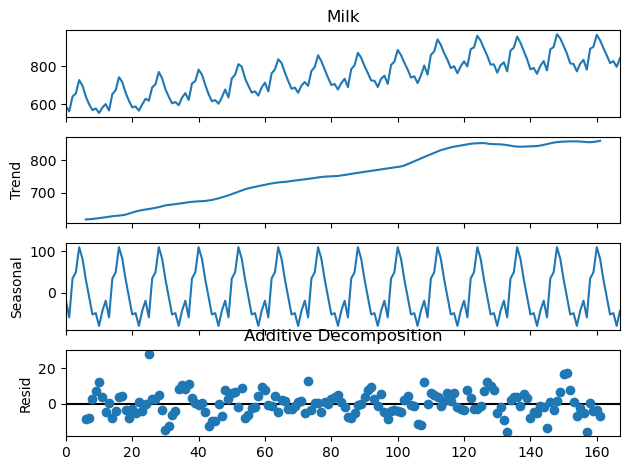

In [4]:
series = df['Milk']

# 2. Perform Decomposition 'additive'
result = seasonal_decompose(series, model='additive',period=12)
result.plot()
plt.title("Additive Decomposition")
plt.show()

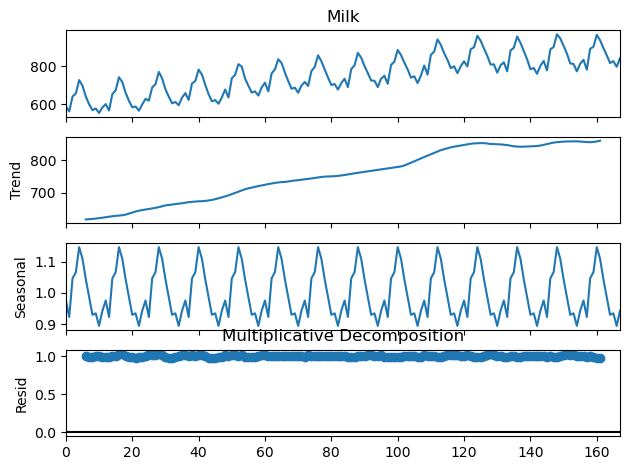

In [5]:
# 2. Perform Decomposition 'multiplicative'
result = seasonal_decompose(series, model='multiplicative',period=12)
result.plot()
plt.title("Multiplicative Decomposition")
plt.show()

Resampling to Quaterly
-

C:\Users\dbda.STUDENTSDC\AppData\Local\Temp\ipykernel_10456\2481227779.py:3: FutureWarning: Resampling with a PeriodIndex is deprecated. Cast index to DatetimeIndex before resampling instead.
  df_qtr = df.resample("Q").sum() # SUM /MEAN


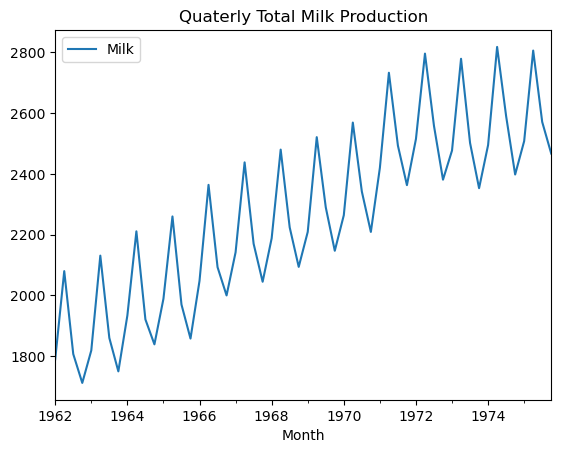

In [6]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv", index_col=0)
df.index = pd.to_datetime(df.index).to_period("M")
df_qtr = df.resample("Q").sum() # SUM /MEAN
df_qtr.plot()
plt.title("Quaterly Total Milk Production")
plt.show()

C:\Users\dbda.STUDENTSDC\AppData\Local\Temp\ipykernel_10456\2991292261.py:1: FutureWarning: Resampling with a PeriodIndex is deprecated. Cast index to DatetimeIndex before resampling instead.
  df_qtr = df.resample("Q").mean()


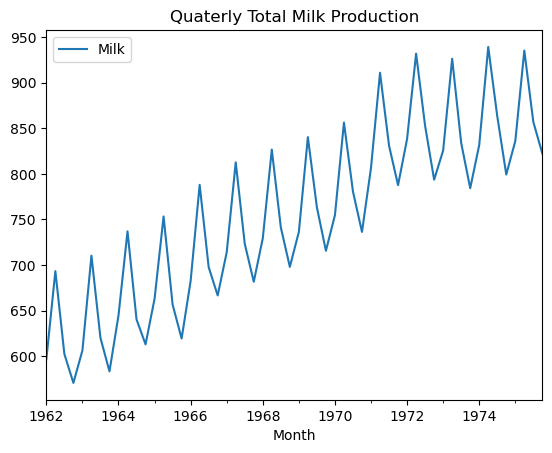

In [7]:
df_qtr = df.resample("Q").mean()
df_qtr.plot()
plt.title("Quaterly Total Milk Production")
plt.show()

Centered Moving Average / Rolling Mean
--

In [8]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv")

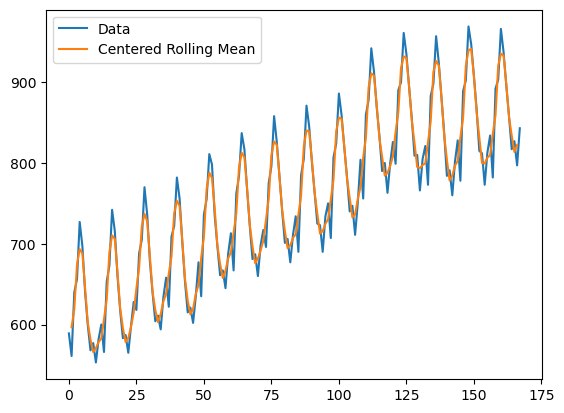

In [9]:
span = 3 # span increased -> smoothening increased
fcast = df['Milk'].rolling(span,center=True).mean()
plt.plot(df['Milk'],label='Data')
plt.plot(fcast, label='Centered Rolling Mean')
plt.legend(loc='best')
plt.show()

Trailing Rolling Mean
--

Train Test split

In [10]:
y_train = df['Milk'][:-12] # everything except the last 12 observations.
y_test = df['Milk'][-12:] # last 12 observations

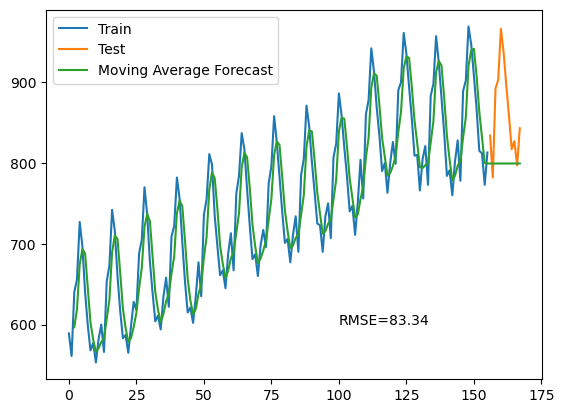

In [11]:
span = 3 # Time window
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast,MA_series],ignore_index=True)
plt.plot(y_train, label='Train')
plt.plot(y_test,label='Test')
plt.plot(MA_fcast,label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test, MA_series),2)
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

.. Span Size   |     Effect on Model,       |      RMSE Outcome

1. Too Small   |    Overfits to noise,      |       High RMSE (Model is too jumpy)
2. Sweet Spot  |  Balances noise & trend    |       Lowest RMSE
3. Too Large   |     Too much lag           |   High RMSE (Model is too slow to react)

## Simple Exponential Method

In [12]:
from statsmodels.tsa.api import SimpleExpSmoothing

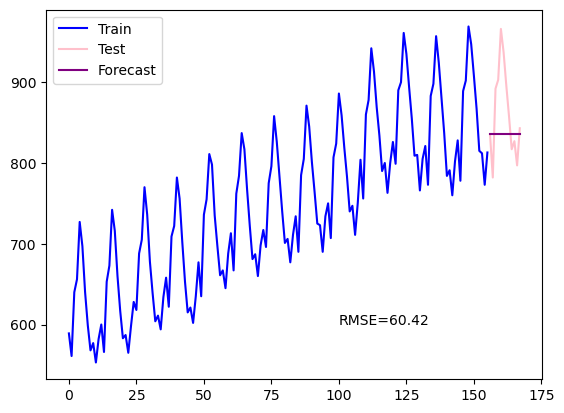

In [13]:
alpha = 0.2
ses_model = SimpleExpSmoothing(y_train).fit(smoothing_level=alpha,optimized=False)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters & optimized =True

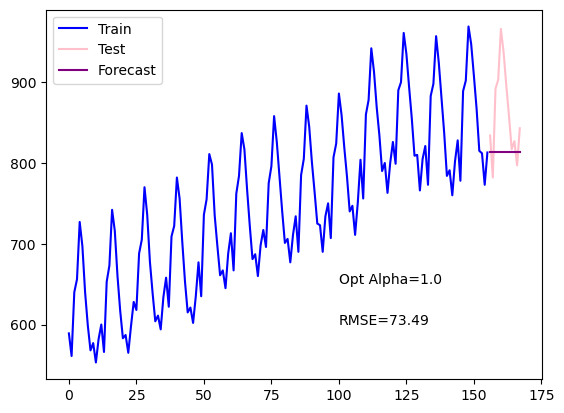

In [14]:
ses_model = SimpleExpSmoothing(y_train).fit(optimized=True)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
opt_alpha = np.round(ses_model.model.params['smoothing_level'],2)
plt.text(100,650,f"Opt Alpha={opt_alpha}")
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Holt's Linear Trend
-

In [15]:
from statsmodels.tsa.api import Holt

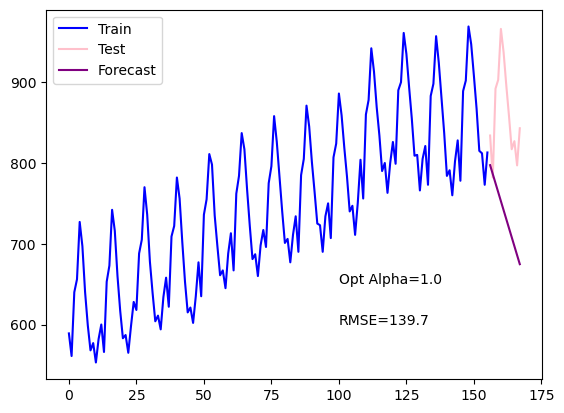

In [16]:
alpha, beta = 0.4,0.2
holt = Holt(y_train)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,650,f"Opt Alpha={opt_alpha}")
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

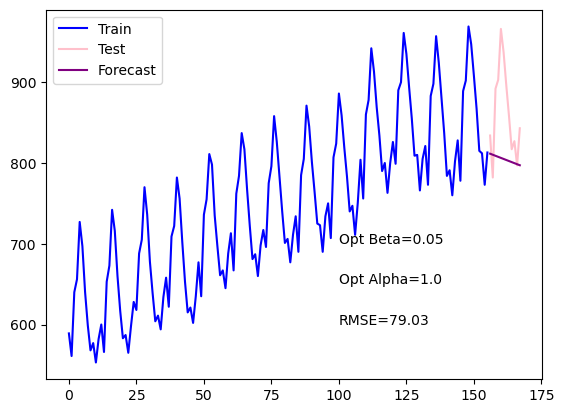

In [17]:
holt = Holt(y_train)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f"RMSE={rms}")
plt.text(100,650,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(100,700,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.legend(loc='best')
plt.show()

Holt's Exponential Trend
--

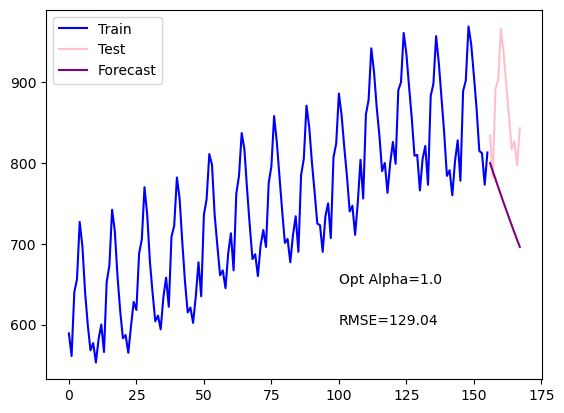

In [18]:
alpha, beta = 0.4,0.2
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,650,f"Opt Alpha={opt_alpha}")
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

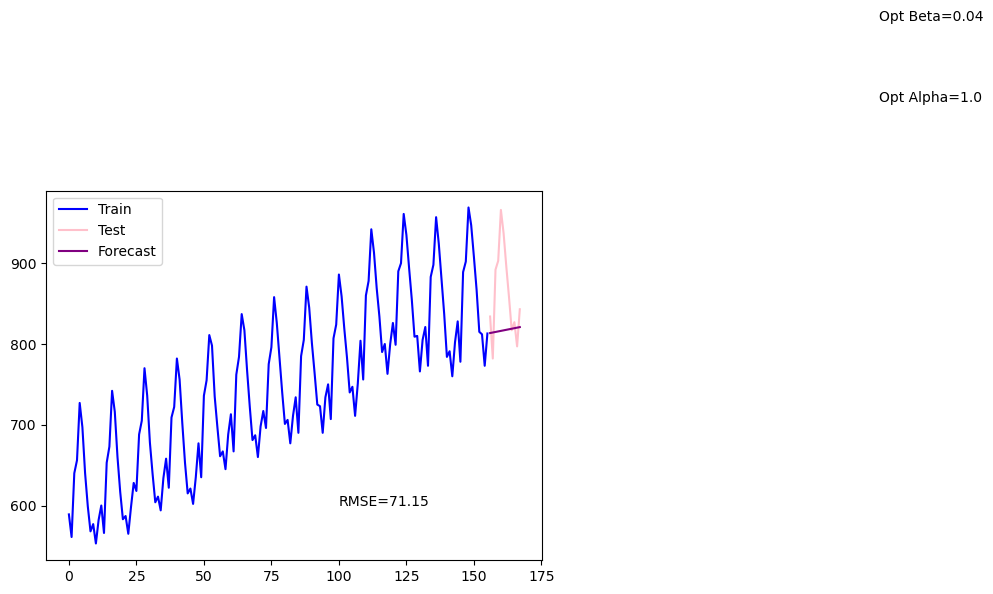

In [19]:
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(300,1100,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(300,1200,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Additive Damp Trend
-

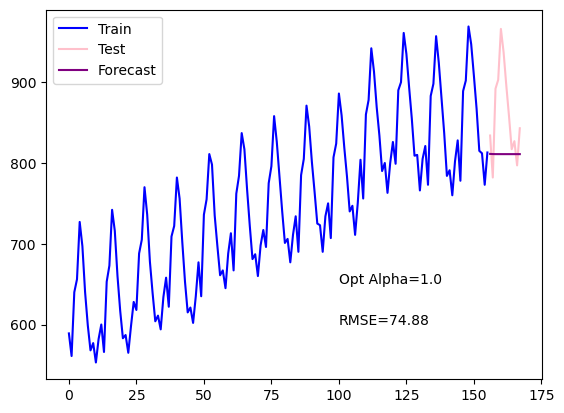

In [20]:
alpha, beta,phi = 0.4,0.2,0.3
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,650,f"Opt Alpha={opt_alpha}")
plt.text(100,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

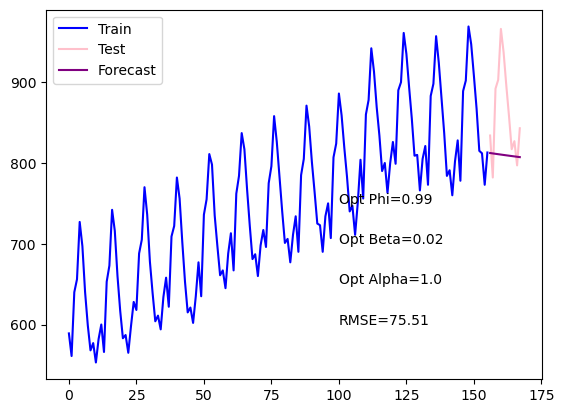

In [21]:
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f"RMSE={rms}")
plt.text(100,650,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(100,700,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(100,750,f"Opt Phi={np.round(fit1.params['damping_trend'], 2)}")
plt.legend(loc='best')
plt.show()

Till above we saw that forecast doesn't match with out train & test. So to match it we will do Exponential Smoothing

Holt Winters Additive Method
-

In [22]:
from statsmodels.tsa.api import ExponentialSmoothing

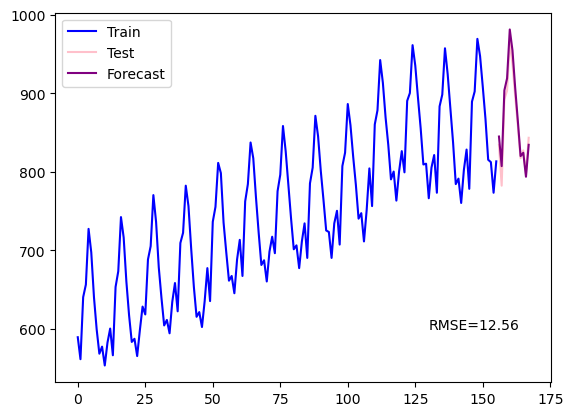

In [23]:
alpa,beta,gamma=0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend='add', seasonal='add')
fit1 =hw_add.fit(smoothing_level=alpha,smoothing_trend=beta,smoothing_seasonal=gamma)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(130,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

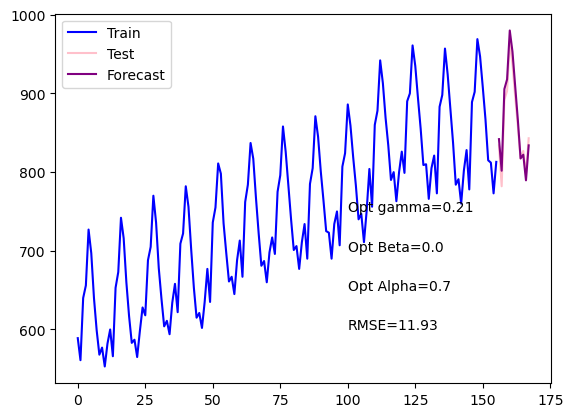

In [24]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend='add', seasonal='add')
fit1 =hw_add.fit(optimized=True)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f"RMSE={rms}")
plt.text(100,650,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(100,700,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(100,750,f"Opt gamma={np.round(fit1.params['smoothing_seasonal'], 2)}")
plt.legend(loc='best')
plt.show()

Holt Winters Multiplicative Method
-

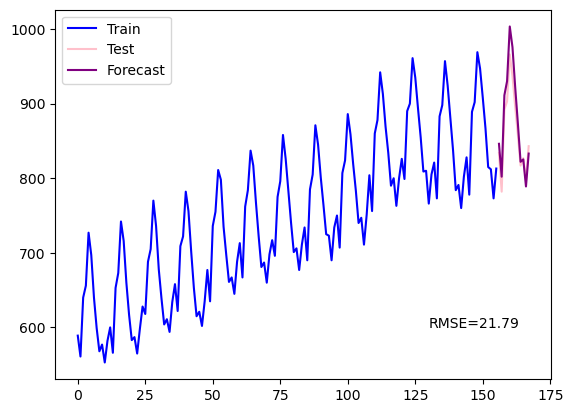

In [25]:
alpa,beta,gamma=0.8,0.02,0.1
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend='add', seasonal='mul')
fit1 =hw_add.fit(smoothing_level=alpha,smoothing_trend=beta,smoothing_seasonal=gamma)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(130,600, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

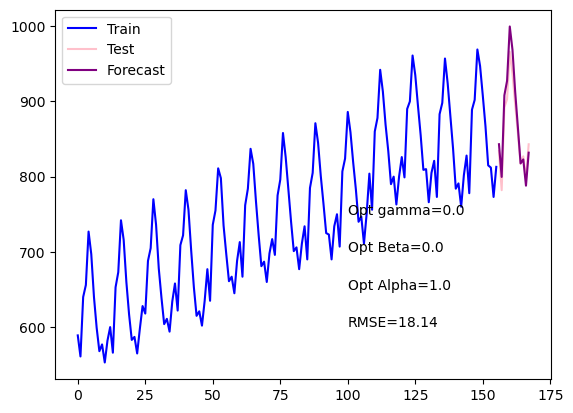

In [26]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend='add', seasonal='mul')
fit1 =hw_add.fit(optimized=True)
fcast1 =fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f"RMSE={rms}")
plt.text(100,650,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(100,700,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(100,750,f"Opt gamma={np.round(fit1.params['smoothing_seasonal'], 2)}")
plt.legend(loc='best')
plt.show()